In [1]:
source('../../../R/preamble.R')

# Replication dynamics (E. coli)
Huang 2023:
https://www.nature.com/articles/s41467-023-37456-2

Matlab code: https://github.com/dean-huang/LagTimeAnalysis/blob/main/Ecoli_FullAnalysis.m

Intuition pump: the number of cells that *just* divided must be twice the number of cells that are about to divide.

* Eq. 3: lag = 1/growth_rate * log(n_ori / n_locus)
* Eq. 4: fork_velocity = d_pos / d_lag = growth_rate / alpha  with alpha = -d(ln(n_locus)) / d_pos

In [2]:
d = read.tsv('../../../datasets/chromosome_replication/coverage_analysis/processed_data_MF_epsilon.tsv') %>% 
    group_by(name) %>%
    mutate(scaled_reads = reads_smooth / n_ter) %>%
    ungroup()

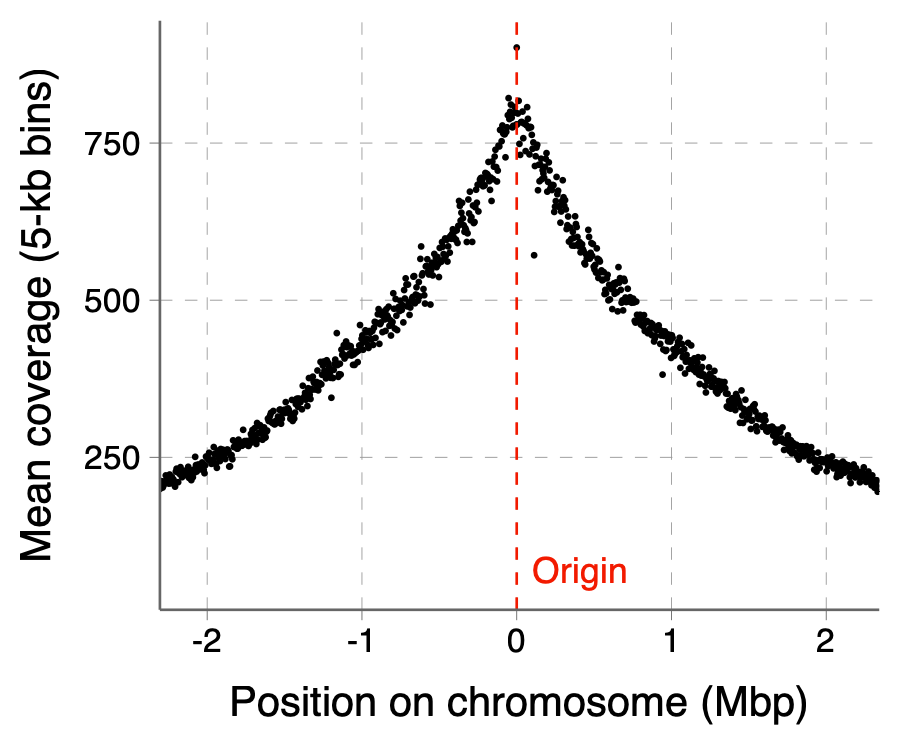

In [3]:
wt_name = 'W'
labels = c('W'='WT', 'R'='rpoS(Y283D)', 'B'='Evolved B (60k)', 'F'='Evolved F (60k)')

# For illustration
size(2.5, 3) 

d %>%
    filter(name == 'W1') %>% 

ggplot() + aes(pos_wrt_ori * 1e-6, reads, group = rep) + 
    
    geom_point(size = 0.1) + 

    xcont() +
    geom_vline(xintercept = 0, lty = 'dashed', lwd = 0.3, col = pal[5]) + 
    annotate(label = 'Origin', geom = 'text', hjust = 0, vjust = 0, x = 0.1, y = 50, size = 3, angle = 0, col = pal[5]) +
    labs(x = 'Position on chromosome (Mbp)', y = 'Mean coverage (5-kb bins)') 

psave('Plots/illustration')

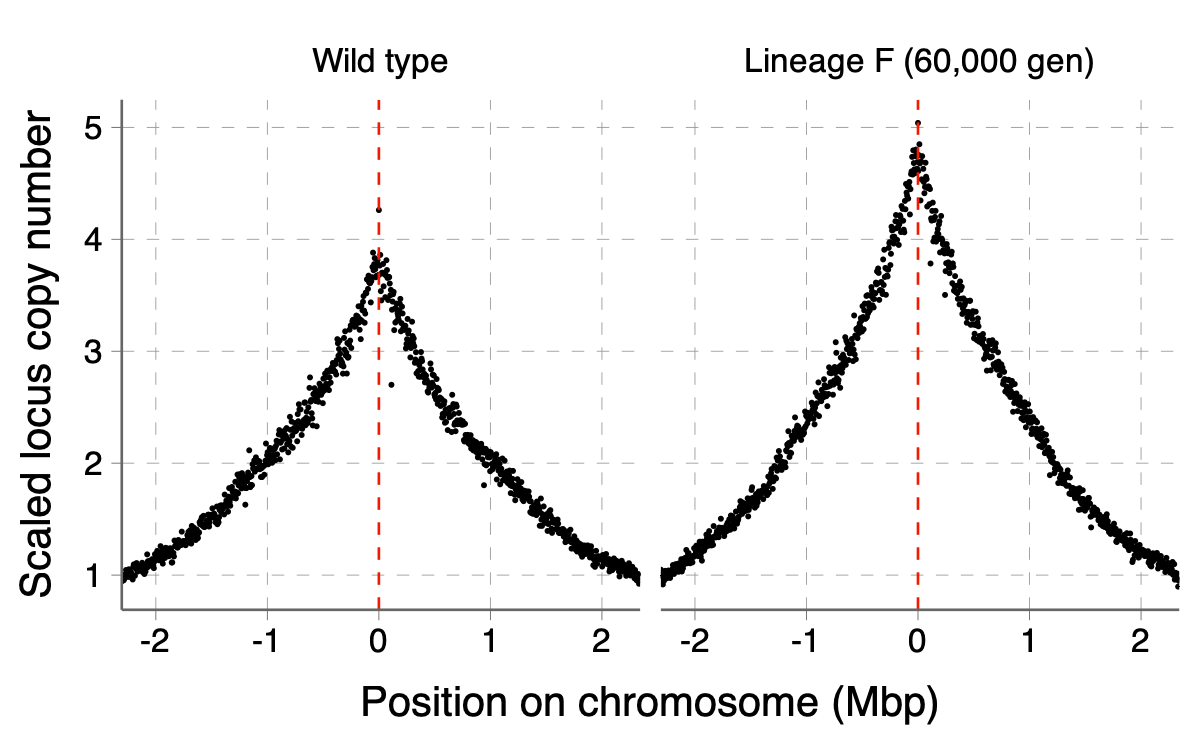

In [4]:
size(2.5, 4)

d$strain_label = factor(d$strain, levels = c('W', 'F'), labels = c('Wild type', 'Lineage F (60,000 gen)'))

W1_vs_F1_illustration_plot =
d %>%
    filter(name %in% c('W1', 'F1')) %>% 

ggplot() + aes(pos_wrt_ori * 1e-6, reads / n_ter, group = rep) + 
    
    facet_grid(~strain_label) +

    geom_point(size = 0.01) + 

    xcont() +

    geom_vline(xintercept = 0, lty = 'dashed', lwd = 0.3, col = pal[5]) + 
    #annotate(label = 'Origin', geom = 'text', hjust = 0, vjust = 0, x = 0.1, y = 50, size = 3, angle = 0, col = pal[5]) +

    labs(x = 'Position on chromosome (Mbp)', y = 'Scaled locus copy number') 

W1_vs_F1_illustration_plot
psave('Plots/W1_vs_F1_illustration')
saveRDS(W1_vs_F1_illustration_plot, file = 'Plots/GG/W1_vs_F1_illustration.rds')

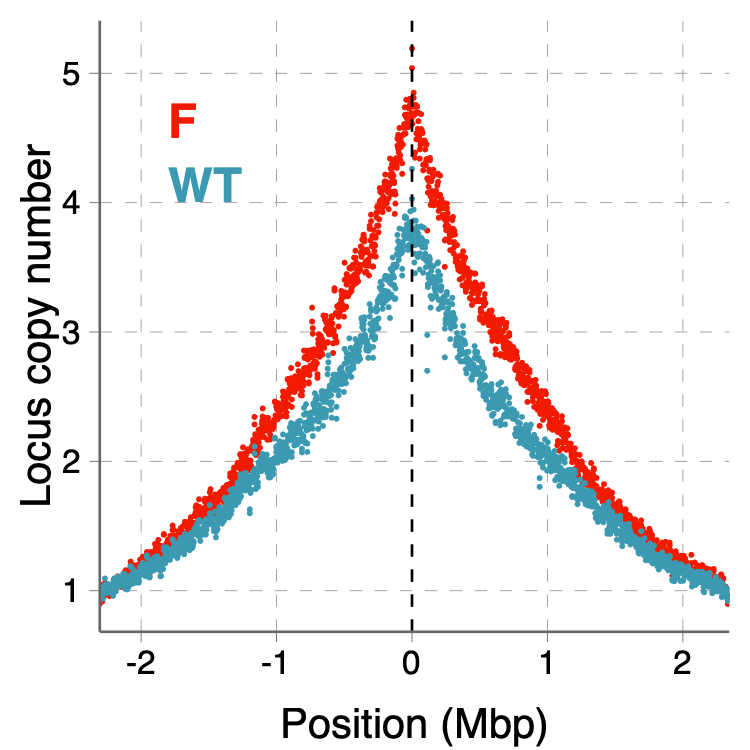

In [5]:
size(2.5, 2.5)

wt_color = pal[1]
f_color = pal[5]

d$strain_label = factor(d$strain, levels = c('W', 'F'), labels = c('Wild type', 'Lineage F (60,000 gen)'))

W1_vs_F1_illustration_compact_plot =
d %>%
    #filter(name %in% c('W1', 'F1')) %>% 
    filter(strain %in% c('W', 'F')) %>% 

ggplot() + aes(pos_wrt_ori * 1e-6, reads / n_ter, group = rep, col = strain) + 
    
    #facet_grid(~strain_label) +

    scale_color_manual(values = c(f_color, wt_color)) + nl +
    annotate(
        geom = 'text',
        x = -1.8, hjust = 0,
        y = c(4, 4.5), vjust = 0,
        col = c(wt_color, f_color), size = 4, fontface = 'bold',
        label = c('WT', 'F')
        ) +

    geom_point(size = 0.01) + 

    xcont() +

    geom_vline(xintercept = 0, lty = 'dashed', lwd = 0.3, col = b) + 
    #annotate(label = 'Origin', geom = 'text', hjust = 0, vjust = 0, x = 0.1, y = 50, size = 3, angle = 0, col = pal[5]) +

    labs(x = 'Position (Mbp)', y = 'Locus copy number') 

W1_vs_F1_illustration_compact_plot
psave('Plots/W1_vs_F1_illustration_compact')
saveRDS(W1_vs_F1_illustration_compact_plot, file = 'Plots/GG/W1_vs_F1_illustration_compact.rds')

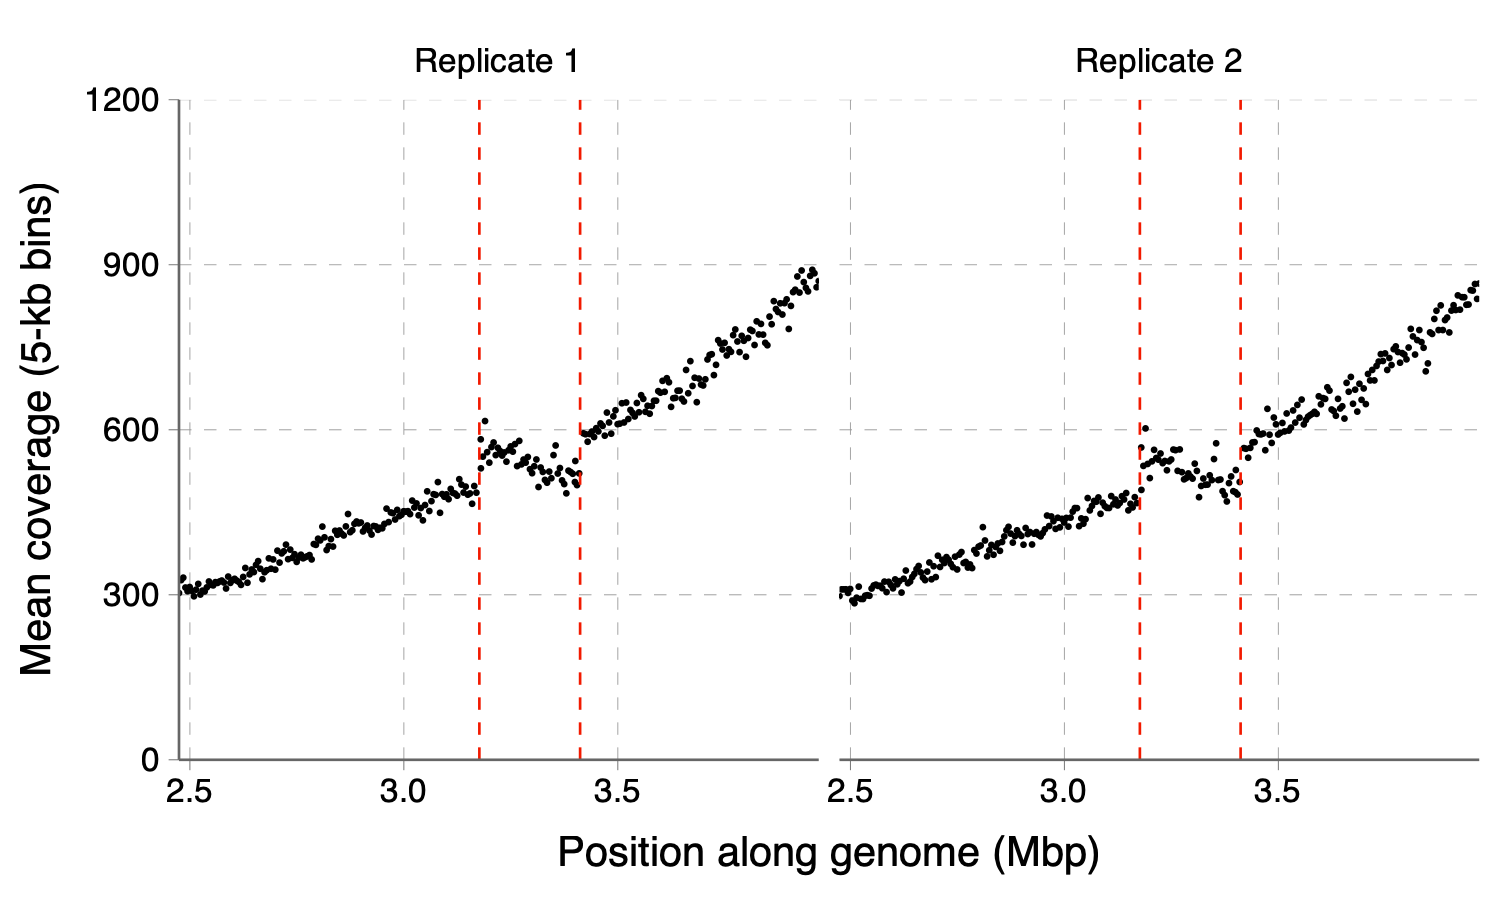

In [6]:
phage_size = 46150
phage_position = 1310570

boundaries = c(3130290, 3365702) + phage_size

inv_start = c(3130290, 3131197) + phage_size # insH9 near yghO
inv_end = c(3365702, 3366607) + phage_size # insH10 near yhcE

# For illustration
size(3, 5) 

d %>%
    filter(
        strain == 'F',
        pos_wrt_ori > -1.5e6,
        pos_wrt_ori < -0.0e6
    ) %>% 

ggplot() + aes(raw_pos*1e-6, reads, group = rep) + 
    
    #geom_line(lwd = 0.2) +
    geom_point(size = 0.1) + 

    facet_wrap(~paste('Replicate', dense_rank(rep))) +

    xcont() + ycont(0, 1200) + small_text + small_titles +

    geom_vline(xintercept = boundaries * 1e-6, lty = 'dashed', lwd = 0.3, col = pal[5]) + 
    #annotate(label = 'origin', geom = 'text', hjust = 0, vjust = 0, x = 0.05, y = 50, size = 3, angle = 0, col = pal[5]) +
    labs(x = 'Position along genome (Mbp)', y = 'Mean coverage (5-kb bins)') 

psave('Plots/inversion_in_F')

# Replication time

In [7]:
ss = read.tsv('../../../datasets/chromosome_replication/coverage_analysis/summary_statistics_MF_epsilon.tsv') %>% mutate(ori_per_ter = n_ori / n_ter)

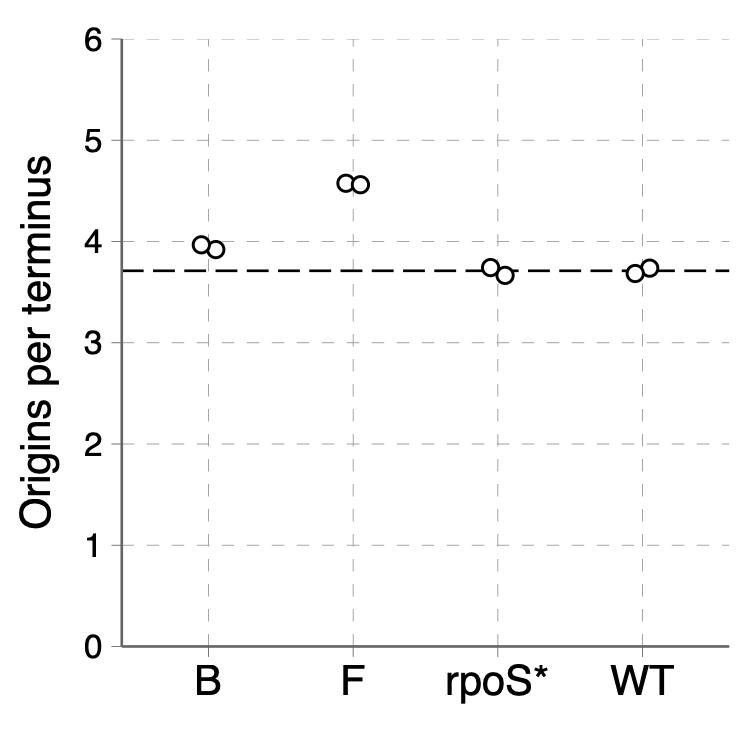

In [8]:
wt_ori_per_ter = mean(ss[ss$strain == 'W',]$ori_per_ter)
                      
labels_short = c('W'='WT', 'R'='rpoS*', 'B'='B', 'F'='F')

size(2.5, 2.5)

dodge = position_dodge(width = 0.2)

ss %>% 
ggplot() + aes(
        labels_short[strain], 
        ori_per_ter,
        group = rep,
        #ymin = errors_min(ori_per_ter), ymax = errors_max(ori_per_ter)
    ) + 
    ycont(0, 6) +
    geom_hline(yintercept = wt_ori_per_ter, lty = 'longdash', linewidth = 0.3, col = b) +

    #geom_errorbar(lwd = 0.3, width = 0.4, position = dodge) +
    geom_point(size = 1.5, pch = 21, fill = w, position = dodge) +
    theme(aspect.ratio = 1, axis.title.x = eb, axis.text.x = element_text(color = b, size = 10)) +

    labs(x = 'Lineage (60,000 gen)', y = 'Origins per terminus')

psave('Plots/ori_per_terminus')

# Plot growth data

In [9]:
g = read.tsv('../../../datasets/chromosome_replication/growth_curves/growth_dynamics_MF_epsilon.tsv')

library(stats)

# Simple spline-based GCV smoothing function
smooth_spline <- function(x, y, df) {

  # Sort by time to ensure proper interpolation
  ord <- order(x)
  x <- x[ord]
  y <- y[ord]
  
  # Perform spline interpolation
  fit <- smooth.spline(
    x = x,
    y = y,
    df = df
  )

  return(predict(fit, x = x)$y)
}

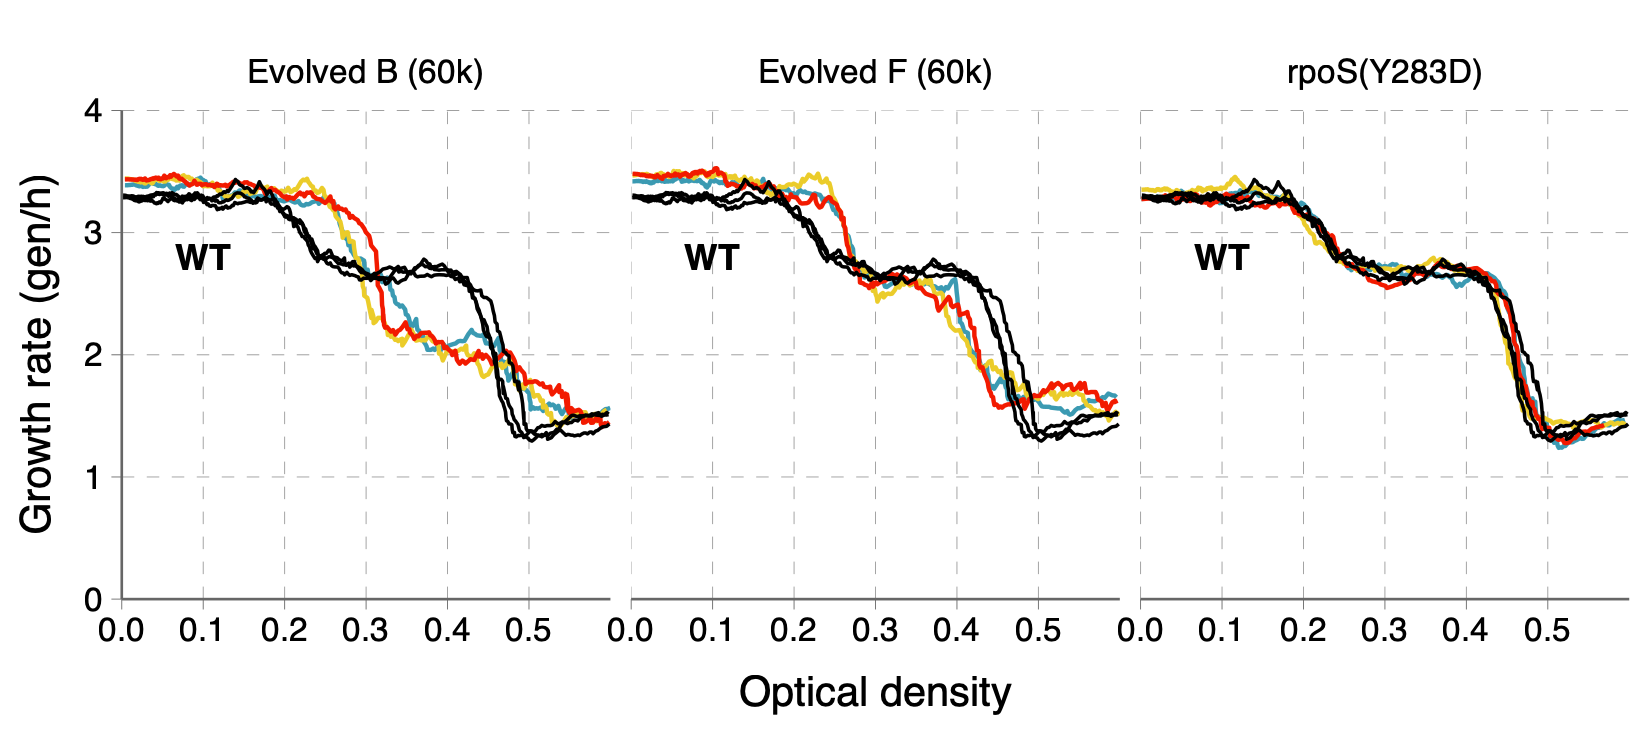

In [10]:
lwd = 0.5
lwd_wt = 0.4

max_od = 0.6

size(2.5, 5.5)

df = 50 # degrees of freedom for smoothing

g_smooth =
g %>%
    group_by(name) %>%
    mutate(
        gr_filt = 60/tau_filt,
        gr_smooth = smooth_spline(o_filt, gr_filt, df)
        ) %>%
    ungroup()

g_trim = g_smooth %>% filter(o_filt <= max_od)

g_trim %>%
    filter(strain != wt_name, strain != 'C') %>% 

ggplot() + aes(o_filt, gr_filt, col = rep, group = name) +
    nl +
    xcont(0, max_od) + ycont(0, 4) +
    facet_wrap(~labels[strain], ncol = 3) +

    geom_line(lwd = lwd) +
    geom_line(data = g_trim %>% filter(strain == wt_name) %>% select(-strain), aes(col = T), col = b, lwd = lwd_wt) +

    annotate(geom = 'text', x = 0.1, y = 2.8, label = 'WT', size = 3, fontface = 'bold', col = b) +
    #annotate(geom = 'text', x = 0.27, y = 3.6, label = '60k', size = 3.5, fontface = 'bold', col = pal[2]) +

    theme(legend.title = eb, aspect.ratio = 1) +

    labs(x = 'Optical density', y = 'Growth rate (gen/h)')

psave('Plots/growth_rate_vs_od')

In [11]:
size(2.5, 4)
contrast = b

d$strain_label = factor(d$strain, levels = c('W', 'B', 'F'), labels = c('Wild type', 'B (60k)', 'F (60k)'))

locus_copy_numbers_plot =
d[sample(nrow(d)), ] %>% 
    filter(
        strain %in% c('W','B','F'),
        reads / n_ter <= 5.2
    ) %>% 

ggplot() + aes(pos_wrt_ori * 1e-6, reads / n_ter, col = rep) +  nl +
    
    facet_grid(~strain_label) +

    geom_point(size = 0.01, alpha = 0.8) + 

    xcont() + ycont(0, 5.2) + 

    theme(panel.grid.major.x=eb, strip.text = element_text(face='bold', size=10)) +
    small_text + small_titles +

    geom_vline(xintercept = 0, lty = 'dashed', lwd = 0.3, col = contrast) + 
    annotate(label = 'ori', geom = 'text', hjust = 0, vjust = 0, x = 0.2, y = 0.7, size = 3, angle = 0, col = contrast) +

    labs(x = 'Position on chromosome (Mbp)', y = 'Read count\nper terminus') 

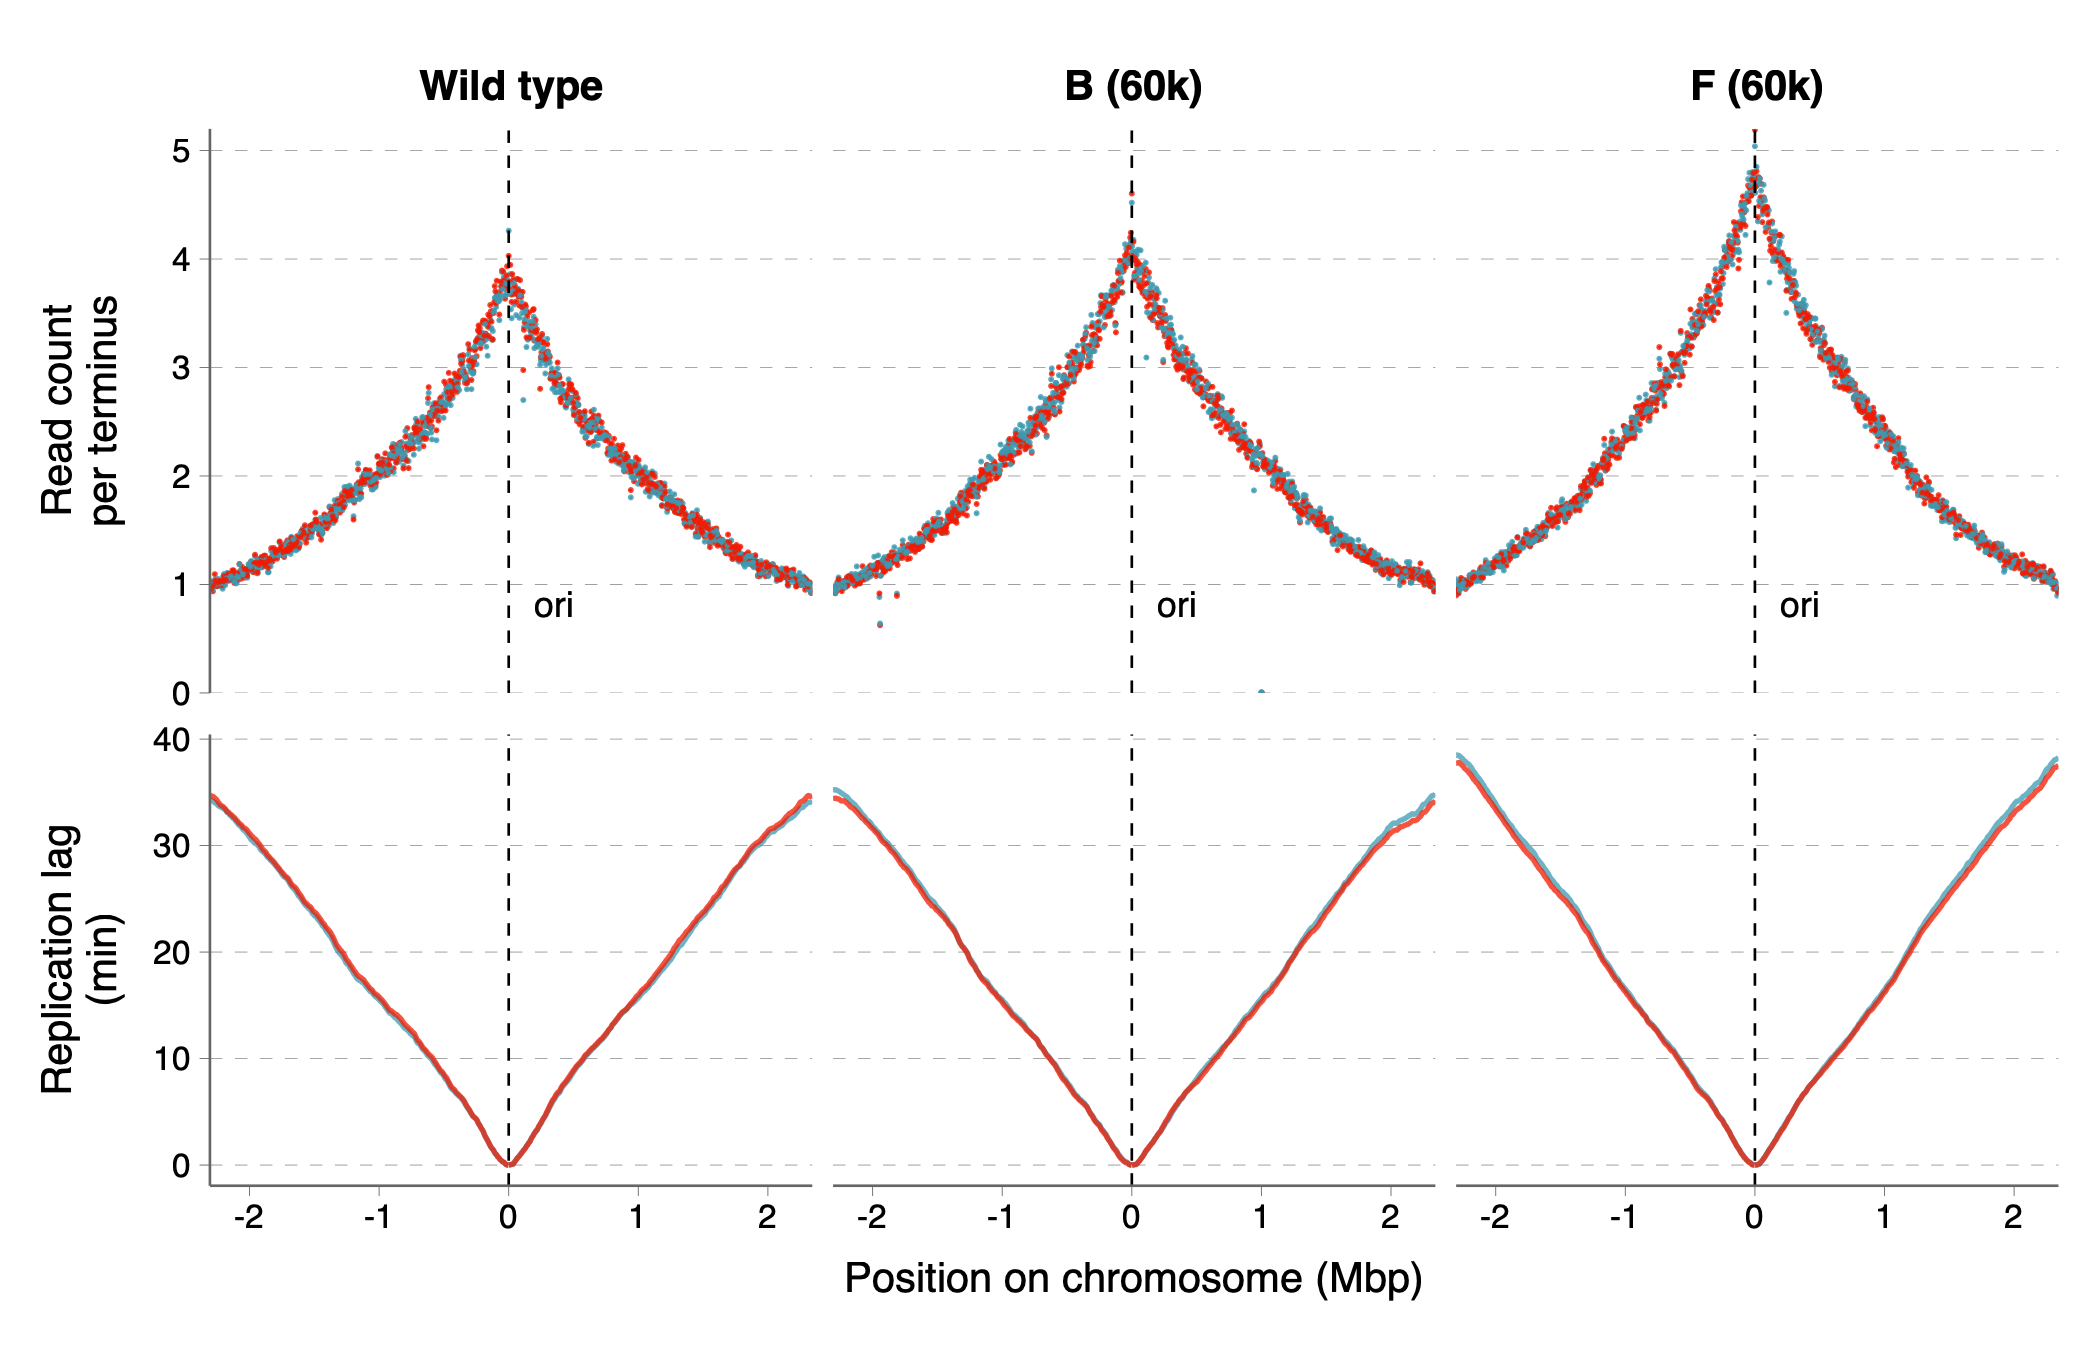

In [12]:
replication_lags_facets_plot =
d %>% 
    filter(strain != 'R') %>%

ggplot() + aes(pos_wrt_ori / 1e6, lag, col = rep, group = paste(name, arm)) + 

    # Evolved strains
    facet_grid(~strain_label) +

    #geom_smooth(lwd = lw, alpha = 0.75, se = F, span = 0.1) +
    #scale_color_manual(values = palette) +
    geom_line(lwd = 0.6, alpha = 0.75) +

    # WT
    #geom_smooth(lwd = lw, data = d %>% filter(strain == wt_name) %>% select(-strain), aes(col = T), col = 'grey30', se = F, span = 0.1) +
    
    #ycont(500, 2500) + 
    xcont() + small_text + small_titles +
    nl +
    geom_vline(xintercept = 0, lty = 'dashed', lwd = 0.3, col = contrast) + 
    theme(strip.text = eb, panel.grid.major.x=eb) +

    labs(x = 'Position on chromosome (Mbp)', y = 'Replication lag\n(min)', col = '')

size(4.5, 7)

read_counts_and_replication_lags_plot =
(
    locus_copy_numbers_plot /
    replication_lags_facets_plot
) +
    plot_layout(axes = 'collect', heights = c(1, 0.8))

read_counts_and_replication_lags_plot
saveRDS(locus_copy_numbers_plot, file = 'Plots/GG/locus_copy_numbers.rds')
saveRDS(replication_lags_facets_plot, file = 'Plots/GG/replication_lags_facts.rds')
saveRDS(read_counts_and_replication_lags_plot, file = 'Plots/GG/read_counts_and_replication_lags.rds')

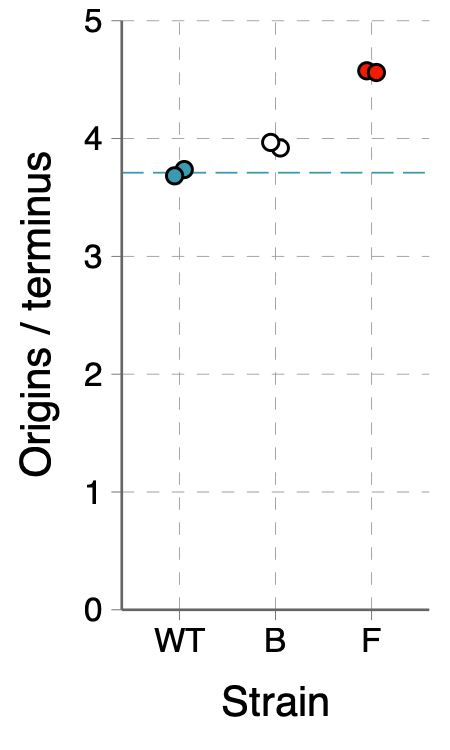

In [13]:
wt_ori_per_ter = mean(ss[ss$strain == wt_name,]$ori_per_ter)

size(2.5, 1.5)

dodge = position_dodge(width = 0.2)

pt_size = 1.5

ori_per_ter_plot =
ss %>% 
    filter(strain %in% c('W', 'B', 'F')) %>% 

ggplot() + aes(
        fct_reorder(labels_short[strain], strain != 'W'),
        ori_per_ter,
        group = rep,
        fill = strain
    ) + 

    nl +
    scale_fill_manual(values = c(w, f_color, wt_color)) +

    ycont(0, 5) +
    geom_hline(yintercept = wt_ori_per_ter, lty = 'longdash', linewidth = 0.2, col = wt_color) +

    #geom_errorbar(lwd = 0.3, width = 0.4, position = dodge) +
    geom_point(size = pt_size, pch = 21, position = dodge) +
    #theme(aspect.ratio = 1) +

    labs(x = 'Strain', y = 'Origins / terminus')# + no_x_title()

ori_per_ter_plot
psave('Plots/ori_per_ter')
saveRDS(ori_per_ter_plot, file = 'Plots/GG/ori_per_ter.rds')

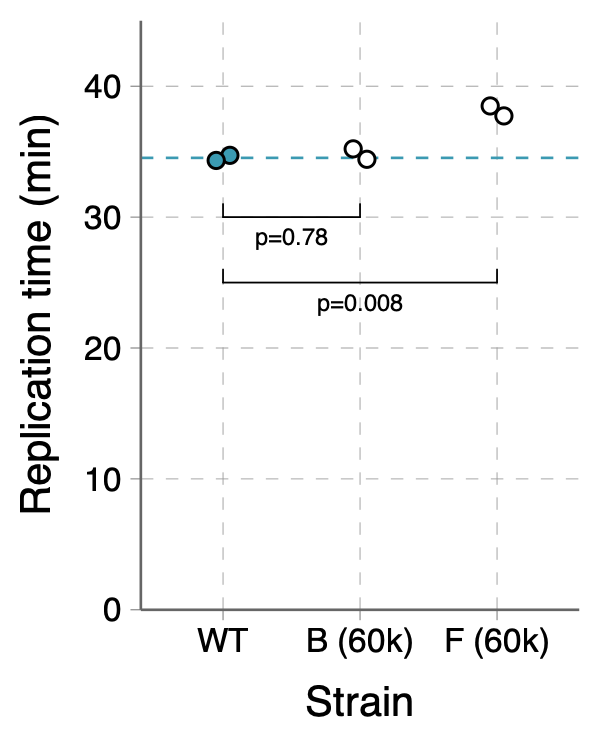

In [14]:
wt_replication_time = mean(ss[ss$strain == wt_name,]$rep_time)
labels_short = c(W='WT', B='B (60k)', F='F (60k)')
dodge = position_dodge(width = 0.2)

size(2.5, 2)

replication_times_plot =
ss %>% 
    filter(strain %in% c('W', 'B', 'F')) %>% 

ggplot() + aes(
        fct_reorder(labels_short[strain], strain != 'W'),
        rep_time,
        group = rep,
        fill = strain == 'W'
    ) + 
    nl +
    scale_fill_manual(values = c(w, wt_color)) +

    ycont(0, 45) +
    geom_hline(yintercept = wt_replication_time, lty = 2, lwd=0.3, col = wt_color) +

    #geom_errorbar(lwd = 0.3, width = 0.4, position = dodge) +
    geom_point(size = pt_size, pch = 21, position = dodge) +
    #theme(aspect.ratio = 1) +

    # Signif
    annotate(
        geom='segment',
        x=c(1,1,2,1,1,3), xend=c(1,2,2,3,1,3), y=c(31,30,31,25,26,26), yend=c(30,30,30,25,25,25),
        lwd = 0.2, col = b, lineend = 'round'
    ) +
    add_text(c(1.5, 2), c(29.2,24.2), c('p=0.78', 'p=0.008'), vjust=1, hjust=0.5, size=2) +

    labs(x = 'Strain', y = 'Replication time (min)') + small_text + small_titles

replication_times_plot
psave('Plots/replication_times')
saveRDS(replication_times_plot, file = 'Plots/GG/replication_times.rds')

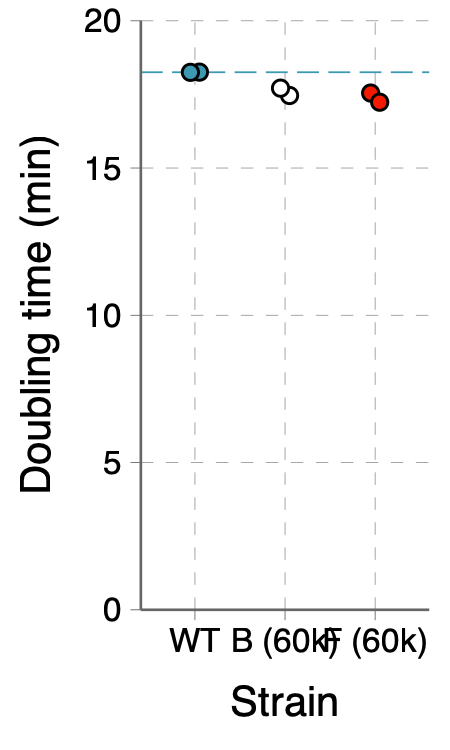

In [15]:
wt_generation_time = mean(ss[ss$strain == wt_name,]$tau)

size(2.5, 1.5)

generation_times_plot =
ss %>% 
    filter(strain %in% c('W', 'B', 'F')) %>% 

ggplot() + aes(
        fct_reorder(labels_short[strain], strain != 'W'),
        tau,
        group = rep,
        fill = strain
    ) + 

    nl + 
    scale_fill_manual(values = c(w, f_color, wt_color)) +
    ycont(0, 20) +
    geom_hline(yintercept = wt_generation_time, lty = 'longdash', linewidth = 0.2, col = wt_color) +

    #geom_errorbar(lwd = 0.3, width = 0.4, position = dodge) +
    geom_point(size = pt_size, pch = 21, position = dodge) +
    #theme(aspect.ratio = 1) +

    labs(x = 'Strain', y = 'Doubling time (min)')# + no_x_title()

generation_times_plot
psave('Plots/generation_times')

**TODO**

When I have expression data, is there a link between position on chromosome and extra expression?

For instance, it could be beneficial to slow down replication, so the Ori/ter balance is more pronounced, so relatively more rRNA is produced (because rRNA are near the origin).

# Replication speed
Remember:
* Eq. 4: fork_velocity = d_pos / d_lag = growth_rate / alpha  with alpha = -d(ln(n_locus)) / d_pos

Huang 2023 and Bhat 2022 (https://elifesciences.org/articles/75884) both observe oscillations in fork velocity. These could be due to:
* Slow-down of forks when a new fork starts, taking some of the dNTP pool for itself
* Delayed feedback between dNTP production and fork requirements

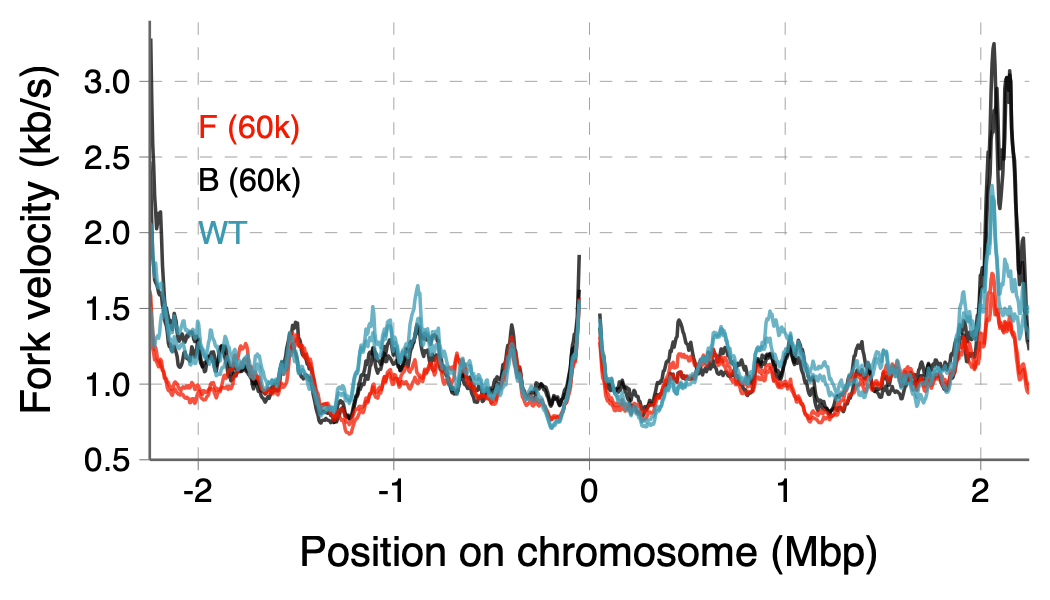

In [16]:
size(2, 3.5)

lw = 0.5
palette = c(b, f_color, wt_color)

fork_velocity_plot =
d %>% 
    filter(strain != 'R', abs(pos_wrt_ori / 1e6) <= 2.25, fv_censored >= 500, fv_censored <= 3400) %>% 

ggplot() + aes(pos_wrt_ori / 1e6, fv_censored / 1e3, col = labels_short[strain], group = paste(name, arm)) + 

    # Evolved strains

    #geom_smooth(lwd = lw, alpha = 0.75, se = F, span = 0.1) +
    scale_color_manual(values = palette) +
    geom_line(lwd = 0.4, alpha = 0.75) +

    # WT
    #geom_smooth(lwd = lw, data = d %>% filter(strain == wt_name) %>% select(-strain), aes(col = T), col = 'grey30', se = F, span = 0.1) +
    
    ycont(500/1e3, 3400/1e3) + 
    xcont() +
    theme(legend.title = eb) + nl +

    annotate(
        geom = 'text', size = 2.7, hjust = 0,#fontface = 'bold',
        label = c('WT', 'B (60k)', 'F (60k)'),
        x = -2,
        y = seq(2, 2.7, length.out=3),
        col = c(wt_color, b, f_color)
        ) +
    #theme(legend.position = c(0.15, 0.75), legend.title = eb, legend.box.background = element_rect(color = 'grey80', linewidth = 1)) +

    labs(x = 'Position on chromosome (Mbp)', y = 'Fork velocity (kb/s)', col = '')

fork_velocity_plot
psave('Plots/fork_velocity')